# NumCompute streaming decision tree demo

In [1]:
from pathlib import Path
import sys
import numpy as np
ROOT = Path.cwd()
if not (ROOT / "numcompute_stream").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "numcompute_stream").is_dir():
    raise RuntimeError("Open this notebook from the project root or demo folder.")
sys.path.insert(0, str(ROOT))

from numcompute_stream.io import iter_csv_chunks
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import SimpleImputer
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.visualise import (
    plot_metric_over_time,
    compare_models,
    plot_predictions_vs_ground_truth,
)

CSV_PATH = ROOT / "demo" / "sample_data.csv"
print("Dataset:", CSV_PATH.name)
print("Features: age, income, hours | Prediction target: plan")

Dataset: sample_data.csv
Features: age, income, hours | Prediction target: plan


In [2]:
def read_plan_chunks():
    """Read two CSV rows at a time and yield labelled examples."""
    reader = iter_csv_chunks(
        CSV_PATH,
        chunk_size=2,
        skip_header=1,
        usecols=(0, 1, 2, 4),
        dtype=str,
    )

    for rows in reader:
        # A blank plan means we don't know the correct answer for that row.
        labelled = rows[rows[:, 3] != ""]
        if len(labelled) == 0:
            continue

        raw_features = labelled[:, :3]
        missing = np.isin(raw_features, ["", "NA"])
        X = np.where(missing, "nan", raw_features).astype(float)
        y = labelled[:, 3]
        yield X, y


for number, (X, y) in enumerate(read_plan_chunks(), start=1):
    print(f"Chunk {number}: {len(y)} labelled rows | plans: {y.tolist()}")

Chunk 1: 2 labelled rows | plans: ['basic', 'premium']
Chunk 2: 2 labelled rows | plans: ['premium', 'basic']
Chunk 3: 1 labelled rows | plans: ['basic']
Chunk 4: 2 labelled rows | plans: ['premium', 'standard']
Chunk 5: 2 labelled rows | plans: ['basic', 'premium']
Chunk 6: 2 labelled rows | plans: ['standard', 'standard']


In [3]:
def make_trainer(buffer_size):
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("tree", DecisionTreeClassifier(max_depth=3, buffer_size=buffer_size)),
    ])
    return StreamTrainer(pipeline)


# Recreate both trainers whenever this cell runs.
trainers = {size: make_trainer(size) for size in (2, 4)}
latest_actual = None
latest_predicted = None

print("Logs for the tree with buffer_size=4\n")

for X, y in read_plan_chunks():
    for size, trainer in trainers.items():
        # Capture predictions before the tree sees this chunk's answers.
        if size == 4 and trainer.pipeline.is_fitted_:
            latest_actual = y.copy()
            latest_predicted = trainer.pipeline.predict(X)

        entry = trainer.fit_chunk(X, y)

        if size == 4:
            accuracy = entry["accuracy"]
            cumulative = entry["cumulative_accuracy"]
            score_text = "warm-up" if accuracy is None else f"{accuracy:.0%}"
            total_text = "warm-up" if cumulative is None else f"{cumulative:.0%}"

            print(
                f"Chunk {entry['chunk']} | rows={entry['rows']} | "
                f"buffer after update={entry['buffered_samples']} | "
                f"retrained={entry['retrained']} | accuracy={score_text} | "
                f"cumulative={total_text} | "
                f"Python-traced memory={entry['traced_memory_bytes']} B"
            )

print("\nLatest actual plans:   ", latest_actual.tolist())
print("Latest predicted plans:", latest_predicted.tolist())

Logs for the tree with buffer_size=4

Chunk 1 | rows=2 | buffer after update=2 | retrained=False | accuracy=warm-up | cumulative=warm-up | Python-traced memory=328 B
Chunk 2 | rows=2 | buffer after update=0 | retrained=True | accuracy=warm-up | cumulative=warm-up | Python-traced memory=2502 B
Chunk 3 | rows=1 | buffer after update=1 | retrained=False | accuracy=0% | cumulative=0% | Python-traced memory=292 B
Chunk 4 | rows=2 | buffer after update=3 | retrained=False | accuracy=50% | cumulative=33% | Python-traced memory=304 B
Chunk 5 | rows=2 | buffer after update=0 | retrained=True | accuracy=100% | cumulative=60% | Python-traced memory=3095 B
Chunk 6 | rows=2 | buffer after update=2 | retrained=False | accuracy=0% | cumulative=43% | Python-traced memory=384 B

Latest actual plans:    ['standard', 'standard']
Latest predicted plans: ['basic', 'premium']


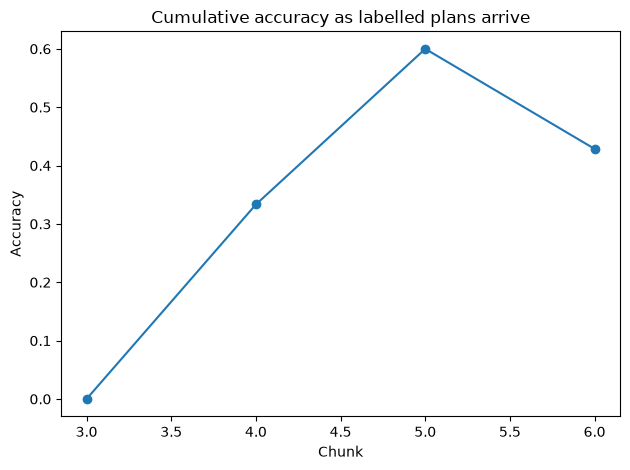

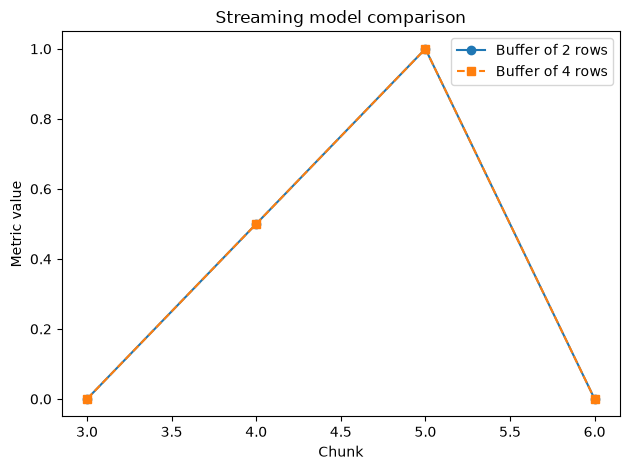

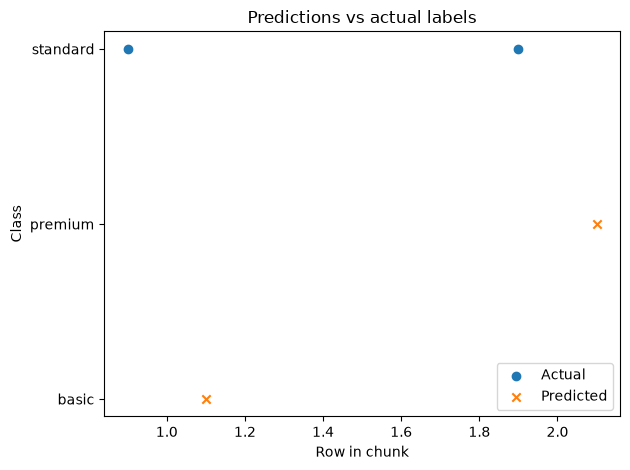

In [4]:
logs_2 = trainers[2].logs
logs_4 = trainers[4].logs

plot_metric_over_time(
    [entry["cumulative_accuracy"] for entry in logs_4],
    title="Cumulative accuracy as labelled plans arrive",
    ylabel="Accuracy",
    show=True,
)

# Compare chunk accuracy only where both trees could make predictions.
small_scores = []
large_scores = []
for small, large in zip(logs_2, logs_4):
    both_ready = small["accuracy"] is not None and large["accuracy"] is not None
    small_scores.append(small["accuracy"] if both_ready else None)
    large_scores.append(large["accuracy"] if both_ready else None)

compare_models(
    small_scores,
    large_scores,
    labels=["Buffer of 2 rows", "Buffer of 4 rows"],
    show=True,
)

plot_predictions_vs_ground_truth(
    latest_actual,
    latest_predicted,
    show=True,
);